## Query Test

In [1]:
import sqlite3, pandas as pd
conn = sqlite3.connect("../database/sales.db")

In [ ]:
# 1
pd.read_sql("""
SELECT c.Region, SUM(s.Sales_Amount) AS Total_Sales
FROM Sales s
INNER JOIN Customers c ON s.Customer_ID = c.Customer_ID
GROUP BY c.Region
ORDER BY Total_Sales DESC;""", conn)

,Region,Total_Sales
0,West,12693550.0
1,South,7464200.0
2,North,6760450.0
3,East,3639500.0


In [3]:
# 2
pd.read_sql("""SELECT p.Product_Name, SUM(s.Sales_Amount) AS Total_Sales, SUM(s.Quantity) AS Units_Sold
FROM Sales s
INNER JOIN Products p ON s.Product_ID = p.Product_ID
GROUP BY p.Product_ID, p.Product_Name
ORDER BY Total_Sales DESC
LIMIT 10;""", conn)

,Product_Name,Total_Sales,Units_Sold
0,Treadmill,1925000.0,55
1,Sofa Set,1728000.0,54
2,Tablet,1344000.0,56
3,Laptop,1248000.0,24
4,Smartphone,1188000.0,66
5,Dining Table,1144000.0,44
6,Bed Frame,1044000.0,58
7,Saree,1040000.0,325
8,Wardrobe,1029000.0,49
9,Cookware Set,1019200.0,364


In [4]:
pd.read_sql("""
SELECT strftime('%Y-%m', Order_Date) AS Month, SUM(Sales_Amount) AS Revenue
FROM Sales
GROUP BY Month
ORDER BY Month;
""", conn)

,Month,Revenue
0,2024-01,875100.0
1,2024-02,1114950.0
2,2024-03,878450.0
3,2024-04,990500.0
4,2024-05,785200.0
5,2024-06,1162400.0
6,2024-07,1083150.0
7,2024-08,1074450.0
8,2024-09,1410350.0
9,2024-10,1686400.0


In [5]:
# 4
pd.read_sql("""
SELECT c.Customer_ID, c.Customer_Name, SUM(s.Sales_Amount) AS Total_Purchase
FROM Sales s
INNER JOIN Customers c ON s.Customer_ID = c.Customer_ID
GROUP BY c.Customer_ID, c.Customer_Name
ORDER BY Total_Purchase DESC
LIMIT 10;
""", conn)

,Customer_ID,Customer_Name,Total_Purchase
0,C136,Vivaan Bose,343500.0
1,C072,Divya Mehta,287100.0
2,C106,Isha Shah,275250.0
3,C193,Sneha Khan,255600.0
4,C298,Suresh Iyer,254600.0
5,C226,Manish Rao,240400.0
6,C259,Karan Patel,237550.0
7,C300,Anjali Verma,236100.0
8,C036,Neha Shah,227100.0
9,C130,Priya Mehta,226750.0


In [8]:
#5
pd.read_sql("""
SELECT p.Category, SUM(s.Sales_Amount) AS Total_Sales
FROM Sales s
INNER JOIN Products p ON s.Product_ID = p.Product_ID
GROUP BY p.Category
ORDER BY Total_Sales DESC;
""", conn)

,Category,Total_Sales
0,Furniture,7084000.0
1,Electronics,6784500.0
2,Sports,5788350.0
3,Home & Kitchen,5579250.0
4,Clothing,5321600.0


In [7]:
# 6
pd.read_sql("""
SELECT c.City, COUNT(s.Order_ID) AS Total_Orders
FROM Sales s
INNER JOIN Customers c ON s.Customer_ID = c.Customer_ID
GROUP BY c.City
ORDER BY Total_Orders DESC;
""", conn)

,City,Total_Orders
0,Ahmedabad,524
1,Mumbai,499
2,Delhi,306
3,Bengaluru,275
4,Jaipur,246
5,Pune,236
6,Chennai,225
7,Kolkata,219
8,Hyderabad,216
9,Patna,120


In [12]:
#7
pd.read_sql("""
SELECT s.Order_ID, s.Order_Date, c.Customer_Name, c.City,
       p.Product_Name, p.Category, s.Quantity, s.Sales_Amount
FROM Sales s
INNER JOIN Customers c ON s.Customer_ID = c.Customer_ID
INNER JOIN Products p  ON s.Product_ID  = p.Product_ID
ORDER BY s.Order_Date
LIMIT 20;
""", conn)

,Order_ID,Order_Date,Customer_Name,City,Product_Name,Category,Quantity,Sales_Amount
0,O00001,2024-01-02,Deepak Reddy,Patna,Iron,Home & Kitchen,4,5600.0
1,O00002,2024-01-02,Neha Mehta,Mumbai,Water Bottle,Home & Kitchen,8,3600.0
2,O00003,2024-01-02,Rohan Verma,Chandigarh,Mixer Grinder,Home & Kitchen,5,16000.0
3,O00004,2024-01-03,Neha Bose,Kolkata,Vacuum Cleaner,Home & Kitchen,2,15000.0
4,O00005,2024-01-03,Aarav Nair,Mumbai,Cycling Helmet,Sports,2,2600.0
5,O00006,2024-01-04,Pooja Khan,Kolkata,Iron,Home & Kitchen,6,8400.0
6,O00007,2024-01-04,Isha Nair,Chennai,Cookware Set,Home & Kitchen,7,19600.0
7,O00008,2024-01-04,Sanjay Mehta,Pune,Electric Kettle,Home & Kitchen,3,3300.0
8,O00009,2024-01-05,Sanjay Sharma,Bengaluru,Water Bottle,Home & Kitchen,1,450.0
9,O00010,2024-01-05,Isha Reddy,Mumbai,Saree,Clothing,1,3200.0


In [ ]:
# 8
pd.read_sql("""
SELECT c.Customer_ID, c.Customer_Name, COUNT(s.Order_ID) AS Total_Orders
FROM Customers c
LEFT JOIN Sales s ON c.Customer_ID = s.Customer_ID
GROUP BY c.Customer_ID, c.Customer_Name
ORDER BY Total_Orders ASC
LIMIT 10;
""", conn)

,Customer_ID,Customer_Name,Total_Orders
0,C120,Rahul Singh,2
1,C195,Suresh Shah,2
2,C123,Rahul Iyer,3
3,C237,Rohan Mehta,3
4,C242,Amit Khan,3
5,C067,Kavya Verma,4
6,C071,Vivaan Mehta,5
7,C077,Anjali Desai,5
8,C092,Isha Singh,5
9,C138,Priya Singh,5


In [11]:
# 9
pd.read_sql("""
SELECT p.Product_Name, COUNT(s.Order_ID) AS Total_Orders
FROM Sales s
RIGHT JOIN Products p ON s.Product_ID = p.Product_ID
GROUP BY p.Product_ID, p.Product_Name
ORDER BY Total_Orders ASC
LIMIT 10;
""", conn)

,Product_Name,Total_Orders
0,Laptop,12
1,Dining Table,21
2,Sofa Set,23
3,Tablet,26
4,Wardrobe,26
5,Treadmill,26
6,Bed Frame,28
7,TV Unit,30
8,Smartphone,33
9,LED Monitor,34


## EDA


In [13]:
query = """
SELECT s.Order_ID, s.Order_Date, s.Quantity, s.Sales_Amount, s.Payment_Mode,
       c.Customer_ID, c.Customer_Name, c.City, c.Region,
       p.Product_ID, p.Product_Name, p.Category, p.Unit_Price
FROM Sales s
INNER JOIN Customers c ON s.Customer_ID = c.Customer_ID
INNER JOIN Products p  ON s.Product_ID  = p.Product_ID
"""
df = pd.read_sql(query, conn)
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Month"] = df["Order_Date"].dt.month
df["Year"]  = df["Order_Date"].dt.year

In [ ]:
print(df.shape)

(3000, 15)

In [17]:
# total Revanue

df["Sales_Amount"].sum()

np.float64(30557700.0)

In [18]:
# Region with highest revenue

df.groupby("Region")["Sales_Amount"].sum().sort_values(ascending=False)

Region
West     12693550.0
South     7464200.0
North     6760450.0
East      3639500.0
Name: Sales_Amount, dtype: float64

In [19]:
# Best product category

df.groupby("Category")["Sales_Amount"].sum().sort_values(ascending=False)

Category
Furniture         7084000.0
Electronics       6784500.0
Sports            5788350.0
Home & Kitchen    5579250.0
Clothing          5321600.0
Name: Sales_Amount, dtype: float64

In [20]:
# Month with highest sales

df.groupby("Month")["Sales_Amount"].sum().sort_values(ascending=False)

Month
10    3448150.0
11    3434250.0
12    3313000.0
9     2649050.0
8     2446750.0
4     2282050.0
6     2258150.0
1     2253800.0
3     2198400.0
2     2157800.0
7     2147450.0
5     1968850.0
Name: Sales_Amount, dtype: float64

In [21]:
# Average order value

df["Sales_Amount"].mean()

np.float64(10185.9)

In [23]:
# Top customers by revenue

df.groupby("Customer_Name")["Sales_Amount"].sum().sort_values(ascending=False).head()

Customer_Name
Vivaan Bose    343500.0
Divya Mehta    287100.0
Isha Shah      275250.0
Sneha Khan     255600.0
Suresh Iyer    254600.0
Name: Sales_Amount, dtype: float64

In [24]:
# Most used payment mode

df["Payment_Mode"].value_counts()

Payment_Mode
UPI            1169
Credit Card     652
Debit Card      562
Cash            346
Net Banking     271
Name: count, dtype: int64

In [29]:
# Yearly growth
yearly = df.groupby("Year")["Sales_Amount"].sum()
print(yearly)
print(yearly.pct_change() * 100)

# Monthly growth
monthly = df.groupby(["Year", "Month"])["Sales_Amount"].sum()
print(monthly.pct_change() * 100)

Year
2024    13938950.0
2025    16618750.0
Name: Sales_Amount, dtype: float64
Year
2024          NaN
2025    19.225264
Name: Sales_Amount, dtype: float64
Year  Month
2024  1              NaN
      2        27.408296
      3       -21.211714
      4        12.755421
      5       -20.726906
      6        48.038716
      7        -6.817791
      8        -0.803213
      9        31.262506
      10       19.573156
      11      -13.389469
      12       -2.957689
2025  1        -2.730351
      2       -24.359904
      3        26.571415
      4        -2.151597
      5        -8.354303
      6        -7.426182
      7        -2.870180
      8        28.939209
      9        -9.735481
      10       42.225721
      11       12.027813
      12       -3.954602
Name: Sales_Amount, dtype: float64


## charts

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

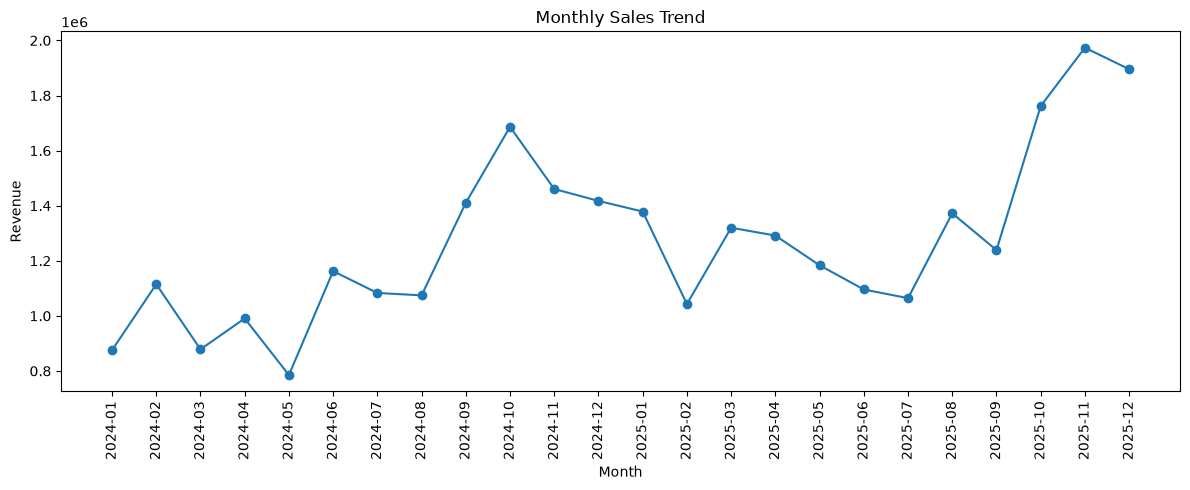

In [31]:
# Monthly sales trend (line)

monthly = df.groupby(df["Order_Date"].dt.to_period("M"))["Sales_Amount"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index.astype(str), monthly.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


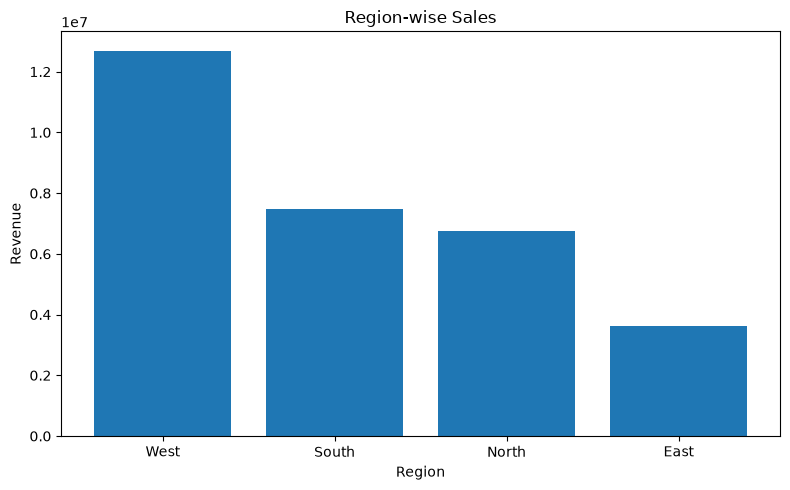

In [32]:
# Region-wise sales (bar)

region_sales = df.groupby("Region")["Sales_Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(region_sales.index, region_sales.values)
plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

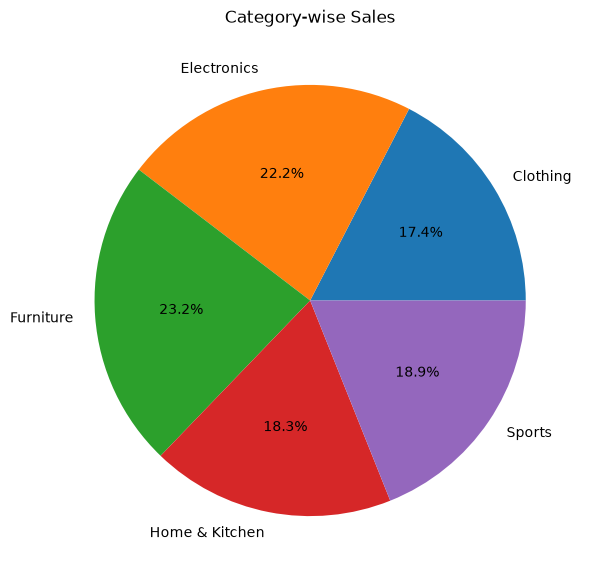

In [33]:
# Category-wise sales (pie)

category_sales = df.groupby("Category")["Sales_Amount"].sum()

plt.figure(figsize=(7, 7))
plt.pie(category_sales.values, labels=category_sales.index, autopct="%1.1f%%")
plt.title("Category-wise Sales")
plt.show()

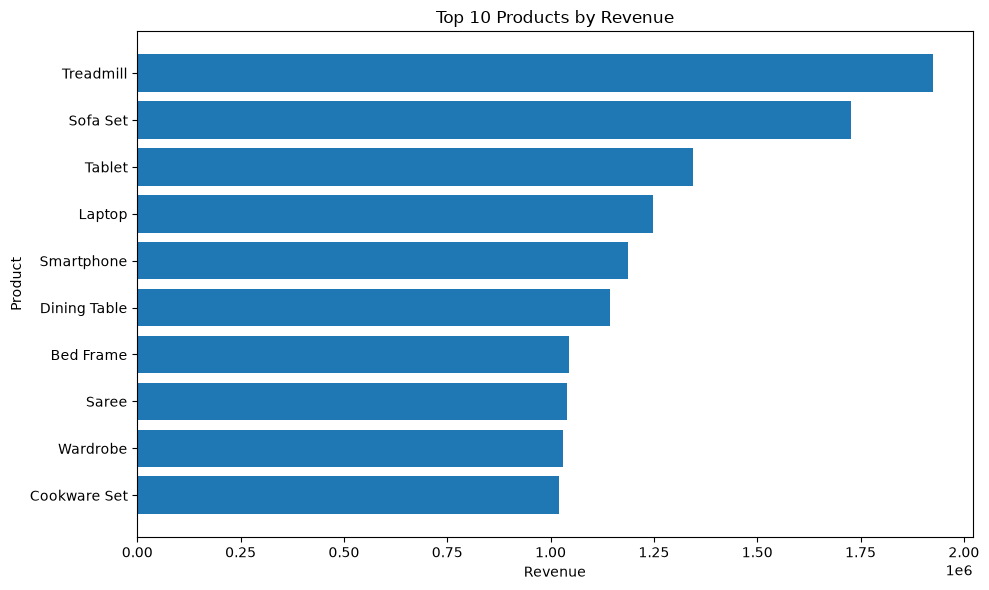

In [34]:
# Product performance (bar)

top_products = df.groupby("Product_Name")["Sales_Amount"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_products.index[::-1], top_products.values[::-1])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

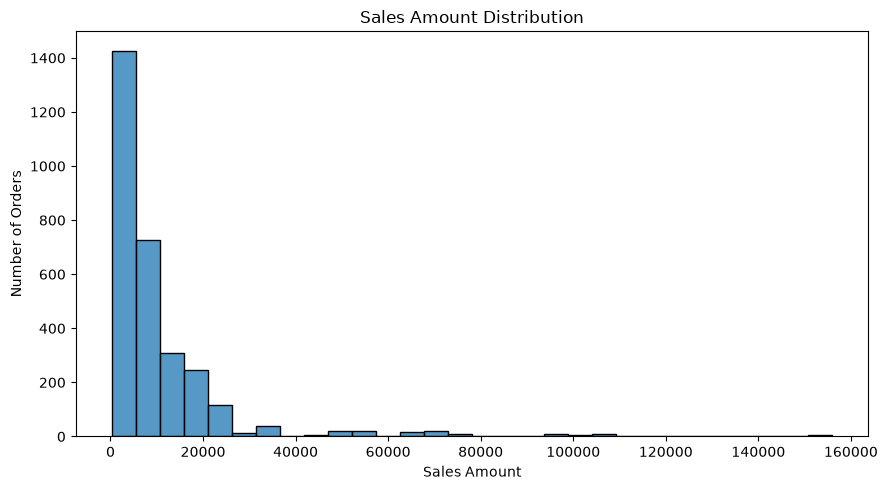

In [35]:
# Sales distribution (histogram)

plt.figure(figsize=(9, 5))
sns.histplot(df["Sales_Amount"], bins=30)
plt.title("Sales Amount Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

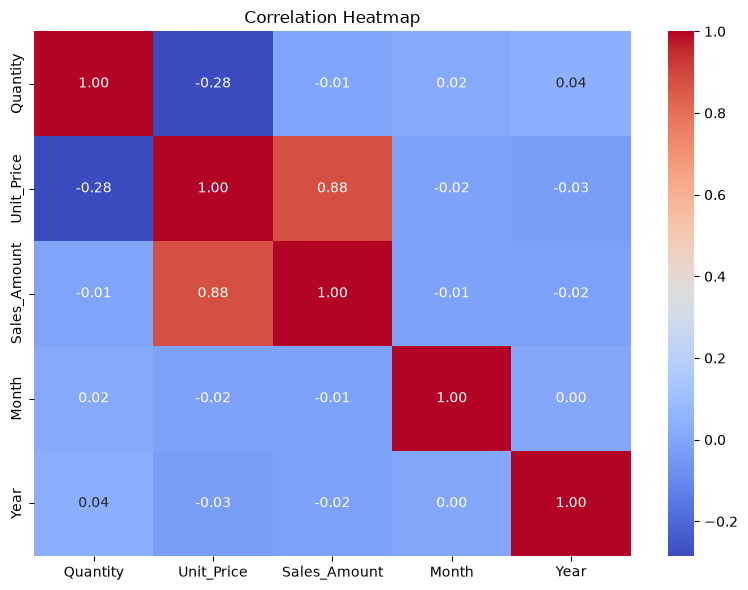

In [36]:
# Correlation (heatmap)

corr = df[["Quantity", "Unit_Price", "Sales_Amount", "Month", "Year"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Sales amount depends mostly on unit price, not quantity.
